# KeypointNet 3D Dataset to Wireframe Swarm Formations

This notebook converts the **KeypointNet** 3D keypoint dataset (16 ShapeNet categories) into a clean, unified wireframe dataset matching the `sample_wireframes.json` schema.

### Pipeline Highlights:
1. **Approach 1 (Semantic Wireframe Templates):** Leverages consistent category `semantic_id`s to automatically synthesize structural edges connecting 3D anchors.
2. **Filtering Constraints:** Excludes any model with more than 20 keypoints (`k <= 20`).
3. **Coordinate Normalization:** Swaps Y and Z axes ($[x, z, y]$) so Z represents vertical altitude for drone swarms, centers each model at the origin, and scales into $[-1.0, 1.0]^3$.
4. **Guaranteed Connectivity:** Ensures zero isolated floating points (degree $\ge 1$ for all anchors).
5. **Perceptual Minimum Drone Calculation:** Calculates the exact minimum drone count ($N_{\min}$) needed for the human eye to perceive the shape correctly without the 'constellation effect'.
6. **3D Swarm Visualization:** Renders 20 diverse 3D formations formed with their exact minimum drone counts.

In [1]:
import os
import glob
import json
import numpy as np
from huggingface_hub import snapshot_download

# 1. Download KeypointNet annotations (only lightweight JSONs, ~40MB)
data_dir = 'data/keypointnet_data' if os.path.exists('data/keypointnet_data') else 'keypointnet_data'
if not os.path.exists(os.path.join(data_dir, 'annotations')):
    print('Downloading KeypointNet annotations from Hugging Face...')
    snapshot_download(
        repo_id='qq456cvb/KeypointNet',
        repo_type='dataset',
        allow_patterns=['annotations/*.json'],
        local_dir=data_dir
    )
    print('Download complete!')
else:
    print('KeypointNet annotations already available locally.')

ann_files = sorted(glob.glob(os.path.join(data_dir, 'annotations', '*.json')))
categories = [os.path.basename(f).replace('.json', '') for f in ann_files if 'all.json' not in f]
print(f'Available categories ({len(categories)}): {categories}')


KeypointNet annotations already available locally.
Available categories (16): ['airplane', 'bathtub', 'bed', 'bottle', 'cap', 'car', 'chair', 'guitar', 'helmet', 'knife', 'laptop', 'motorcycle', 'mug', 'skateboard', 'table', 'vessel']


/home/mnwr/miniconda3/envs/s2f/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Master Semantic Edge Templates for all 16 categories
CATEGORY_TEMPLATES = {
    'airplane': [
        (0, 1), (1, 2), # fuselage spine (nose to tail)
        (0, 4), (0, 6), (1, 4), (1, 6), # nose to wing roots
        (4, 12), (6, 13), (12, 2), (13, 2), # wing roots to tail
        (4, 3), (12, 3), # left wing root to tip
        (6, 5), (13, 5), # right wing root to tip
        (4, 14), (14, 3), # left engine
        (6, 15), (15, 5), # right engine
        (2, 7), (2, 8), # horizontal stabilizers
        (2, 9), (7, 9), (8, 9) # vertical stabilizer fin
    ],
    'chair': [
        (0, 1), (0, 2), (1, 3), # backrest frame
        (2, 3), (3, 5), (5, 4), (4, 2), # seat perimeter
        (4, 17), (2, 18), (3, 19), (5, 20), # 4 legs to feet
        (6, 7), (8, 9), # armrests top bar
        (4, 6), (2, 7), (5, 8), (3, 9), # armrest vertical posts
        (17, 18), (18, 19), (19, 20), (20, 17), # lower leg stretchers
        (10, 15), (11, 15), (12, 15), (13, 15), (14, 15), # swivel base star
        (15, 16) # swivel center post
    ],
    'table': [
        (0, 1), (1, 2), (2, 3), (3, 0), # tabletop perimeter
        (0, 4), (1, 5), (2, 6), (3, 7), # 4 legs to feet
        (4, 5), (5, 6), (6, 7), (7, 4), # lower leg stretchers
        (8, 0), (8, 1), (9, 2), (9, 3) # apron supports
    ],
    'car': [
        (0, 3), (1, 2), (0, 1), (3, 2), # wheels perimeter
        (4, 7), (5, 6), # front/rear bumpers
        (4, 0), (7, 3), (5, 1), (6, 2), # bumpers to wheels
        (12, 13), # hood front edge
        (4, 12), (7, 12), (4, 13), (7, 13), (0, 12), (3, 13), # hood frame
        (8, 9), (9, 10), (10, 11), (11, 8), # roof rectangle
        (12, 8), (13, 11), # windshield A-pillars
        (14, 9), (15, 10), # rear window C-pillars
        (16, 12), (19, 13), (17, 14), (18, 15), # beltline
        (1, 14), (2, 15), (5, 14), (6, 15), # rear trunk
        (8, 16), (11, 19), (9, 17), (10, 18) # door frames
    ],
    'guitar': [
        (0, 1), # headstock to neck junction
        (1, 2), (1, 3), # neck to upper bout shoulders
        (2, 7), (3, 8), # upper bouts to waist
        (7, 4), (8, 5), # waist to lower bouts
        (4, 6), (5, 6) # lower bouts to base endpin
    ],
    'laptop': [
        (0, 3), (3, 2), (2, 1), (1, 0), # keyboard base perimeter
        (1, 4), (2, 5), # screen side hinges
        (4, 5) # screen top bezel
    ],
    'bed': [
        (0, 3), (3, 2), (2, 1), (1, 0), # base feet rectangle
        (4, 7), (7, 6), (6, 5), (5, 4), # mattress perimeter
        (0, 4), (3, 7), (2, 6), (1, 5), # corner vertical posts
        (6, 10), (5, 9), (10, 9), # headboard frame
        (4, 8), (7, 11), (8, 11), # footboard frame
        (10, 14), (9, 13), (14, 13), # tall headboard posts
        (8, 12), (11, 15), (12, 15) # tall footboard posts
    ],
    'bottle': [
        (0, 1), (1, 2), (2, 3), (3, 0), # base ring
        (4, 5), (5, 6), (6, 7), (7, 4), # body shoulder ring
        (0, 4), (1, 5), (2, 6), (3, 7), # vertical body ribs
        (13, 14), (14, 15), (15, 16), (16, 13), # neck base ring
        (4, 13), (5, 14), (6, 15), (7, 16), # shoulder transitions
        (9, 10), (10, 11), (11, 12), (12, 9), # cap lip ring
        (13, 9), (14, 10), (15, 11), (16, 12), # neck vertical ribs
        (9, 8), (10, 8), (11, 8), (12, 8) # cap top apex
    ],
    'mug': [
        (0, 1), (1, 2), (2, 3), (3, 0), # top rim ring
        (4, 5), (5, 6), (6, 7), (7, 4), # bottom base ring
        (0, 4), (1, 5), (2, 6), (3, 7), # cylinder walls
        (8, 9), (9, 10), # handle loop
        (0, 8), (4, 10) # handle joints to body
    ],
    'skateboard': [
        (8, 0), (8, 1), # nose tip to front deck
        (0, 1), (2, 3), # front & rear deck widths
        (0, 3), (1, 2), # deck side rails
        (2, 9), (3, 9), # rear deck to tail tip
        (0, 4), (1, 5), # front truck & wheels
        (3, 7), (2, 6), # rear truck & wheels
        (4, 5), (6, 7) # wheel axles
    ],
    'motorcycle': [
        (9, 4), (9, 7), (4, 7), # front wheel & hub
        (10, 5), (10, 8), (5, 8), # rear wheel & hub
        (4, 0), (7, 0), # front fork to handlebars
        (1, 2), (1, 0), (2, 0), # handlebars
        (0, 12), (0, 11), (11, 3), # front fairing, gas tank, seat
        (3, 13), (13, 10), # seat to tail and rear wheel
        (11, 6), (6, 5), (6, 8), (4, 6), (7, 6) # engine and swingarm
    ],
    'bathtub': [
        (0, 1), (1, 2), (2, 3), (3, 0), # outer top rim
        (8, 9), (9, 10), (10, 11), (11, 8), # inner top rim
        (0, 8), (1, 9), (2, 10), (3, 11), # rim width
        (4, 5), (5, 6), (6, 7), (7, 4), # outer bottom base
        (12, 13), (13, 14), (14, 15), (15, 12), # inner floor
        (0, 4), (1, 5), (2, 6), (3, 7), # outer corner posts
        (8, 12), (9, 13), (10, 14), (11, 15) # inner corner posts
    ],
    'cap': [
        (0, 1), (0, 2), (0, 3), (0, 4), # crown apex to headband
        (2, 4), (3, 4), # back headband
        (2, 5), (3, 5), # front headband
        (5, 1), (2, 1), (3, 1) # visor brim
    ],
    'helmet': [
        (0, 1), (0, 2), (0, 3), (0, 4), # crown dome
        (1, 3), (1, 4), (2, 3), (2, 4), # middle rim
        (3, 5), (4, 6), (1, 7), (2, 8), # lower rim / jaw
        (5, 7), (6, 7), (5, 8), (6, 8) # chin & nape
    ],
    'knife': [
        (1, 2), (1, 3), (2, 3), # handle pommel to hilt
        (2, 0), (3, 0), # hilt to blade tip
        (4, 0), (5, 0), (4, 2), (5, 3) # blade edges
    ],
    'vessel': [
        (0, 1), (0, 4), # bow to forward deck
        (1, 5), (4, 8), (5, 8), # deck sheerline perimeter
        (0, 2), (0, 3), # bow to forward keel
        (2, 6), (3, 7), (6, 7), # keel & waterline
        (1, 2), (4, 3), (5, 6), (8, 7), # hull ribs
        (9, 10), # mast / cabin top
        (1, 9), (4, 9), (5, 9), (8, 9), # cabin to deck
        (11, 13), (12, 14), (13, 14), (11, 12), # deckhouse
        (15, 17), (16, 18), (17, 18), (15, 16), # superstructure
        (11, 15), (12, 16), (13, 17), (14, 18)
    ]
}

def convert_dataset():
    ann_dir = 'keypointnet_data/annotations'
    dataset = {}
    category_counts = {}

    for cat_stem, template in CATEGORY_TEMPLATES.items():
        json_path = os.path.join(ann_dir, f'{cat_stem}.json')
        if not os.path.exists(json_path):
            continue
        with open(json_path) as f:
            models = json.load(f)

        cat_display = 'vessel_boat' if cat_stem == 'vessel' else cat_stem
        category_counts[cat_display] = 0

        for idx, m in enumerate(models):
            kps = m.get('keypoints', [])
            # Constraint: Exclude models with > 20 keypoints (and ignore degenerate models < 4)
            if not (4 <= len(kps) <= 20):
                continue

            # Sort keypoints by semantic_id for consistent ordering
            kps_sorted = sorted(enumerate(kps), key=lambda x: x[1].get('semantic_id', 0))
            sem_to_idx = {kp['semantic_id']: new_idx for new_idx, (_, kp) in enumerate(kps_sorted)}

            # Swap Y and Z: [x, y, z] -> [x, z, y] so Z is altitude for drones
            coords = []
            for _, kp in kps_sorted:
                x, y, z = kp['xyz']
                coords.append([x, z, y])
            coords = np.array(coords, dtype=float)

            # Centering & Normalization into [-1.0, 1.0]^3
            centroid = np.mean(coords, axis=0)
            coords = coords - centroid
            max_norm = np.max(np.linalg.norm(coords, axis=1)) + 1e-8
            coords = np.round(coords / max_norm, 3).tolist()

            # Generate edges from category semantic template
            edges_set = set()
            for s1, s2 in template:
                if s1 in sem_to_idx and s2 in sem_to_idx:
                    i, j = sem_to_idx[s1], sem_to_idx[s2]
                    if i != j:
                        edges_set.add((min(i, j), max(i, j)))

            # Ensure 100% connectivity: connect any isolated anchor to its nearest neighbor
            K = len(coords)
            connected = set()
            for i, j in edges_set:
                connected.add(i)
                connected.add(j)

            coords_arr = np.array(coords)
            for i in range(K):
                if i not in connected:
                    dists = np.linalg.norm(coords_arr - coords_arr[i], axis=1)
                    dists[i] = np.inf
                    nearest = int(np.argmin(dists))
                    edges_set.add((min(i, nearest), max(i, nearest)))
                    connected.add(i)
                    connected.add(nearest)

            model_id = m.get('model_id', f'{idx:04d}')
            shape_key = f'{cat_display}_{model_id[:8]}'
            description = f'3D {cat_display} wireframe formation with {K} structural anchors and {len(edges_set)} connecting edges'

            dataset[shape_key] = {
                'category': cat_display,
                'model_id': model_id,
                'description': description,
                'anchors': coords,
                'edges': sorted([list(e) for e in edges_set])
            }
            category_counts[cat_display] += 1

    output_filename = 'data/keypointnet_wireframes.json'
    with open(output_filename, 'w') as f:
        json.dump(dataset, f, indent=2)

    print(f'=== Successfully Generated Dataset: {output_filename} ===')
    print(f'Total 3D models converted: {len(dataset):,}')
    print(f'File size: {os.path.getsize(output_filename) / (1024*1024):.2f} MB')
    return dataset, category_counts

dataset, category_counts = convert_dataset()


=== Successfully Generated Dataset: keypointnet_wireframes.json ===
Total 3D models converted: 7,454
File size: 11.64 MB


In [3]:
print(f'{"Category":15s} | {"Models":8s} | {"Anchor Range":14s} | {"Avg Anchors":12s} | {"Avg Edges":10s}')
print('-' * 70)

for cat, count in category_counts.items():
    cat_models = [data for k, data in dataset.items() if data.get('category') == cat]
    if not cat_models: continue
    anchor_counts = [len(m['anchors']) for m in cat_models]
    edge_counts = [len(m['edges']) for m in cat_models]
    min_k, max_k = min(anchor_counts), max(anchor_counts)
    avg_k = np.mean(anchor_counts)
    avg_e = np.mean(edge_counts)
    print(f'{cat:15s} | {count:8d} | [{min_k:2d}, {max_k:2d}] anchors | {avg_k:12.1f} | {avg_e:10.1f}')

total_anchors = sum(len(m['anchors']) for m in dataset.values())
total_edges = sum(len(m['edges']) for m in dataset.values())
print('-' * 70)
print(f'{"TOTAL":15s} | {len(dataset):8d} | [4, 20] anchors | {total_anchors/len(dataset):12.1f} | {total_edges/len(dataset):10.1f}')


Category        | Models   | Anchor Range   | Avg Anchors  | Avg Edges 
----------------------------------------------------------------------
airplane        |     1022 | [ 5, 17] anchors |         13.5 |       21.3
chair           |      999 | [ 8, 17] anchors |         12.1 |       17.6
table           |     1124 | [ 7, 12] anchors |          8.0 |       12.1
car             |      277 | [14, 20] anchors |         19.7 |       33.5
guitar          |      697 | [ 4,  9] anchors |          8.5 |        8.2
laptop          |      439 | [ 6,  6] anchors |          6.0 |        7.0
bed             |      146 | [ 8, 16] anchors |         12.6 |       18.3
bottle          |      380 | [ 4, 18] anchors |         16.5 |       30.4
mug             |      186 | [10, 11] anchors |         11.0 |       16.0
skateboard      |      141 | [ 6, 10] anchors |          9.4 |       13.0
motorcycle      |      298 | [ 7, 14] anchors |         13.0 |       18.8
bathtub         |      438 | [ 8, 20] ancho

Selected 20 3D wireframe samples across categories:
  1. airplane_51ebcde4      (12 anchors, 19 edges)
  2. chair_8d458ab1         (17 anchors, 19 edges)
  3. table_5f4c30f8         (8 anchors, 12 edges)
  4. car_61c4db4c           (20 anchors, 37 edges)
  5. guitar_3338f59a        (9 anchors, 9 edges)
  6. laptop_6489453e        (6 anchors, 7 edges)
  7. bed_6cda6495           (16 anchors, 24 edges)
  8. bottle_970027a2        (17 anchors, 32 edges)
  9. mug_8b1dca14           (11 anchors, 16 edges)
 10. skateboard_7a8b7d5d    (10 anchors, 14 edges)
 11. motorcycle_f0c70431    (14 anchors, 21 edges)
 12. bathtub_198abf39       (18 anchors, 30 edges)
 13. cap_30be60f9           (6 anchors, 11 edges)
 14. helmet_96366015        (9 anchors, 16 edges)
 15. knife_102982a2         (6 anchors, 9 edges)
 16. vessel_boat_dc422a7f   (18 anchors, 27 edges)
 17. airplane_8fe406a8      (9 anchors, 11 edges)
 18. car_202648a8           (20 anchors, 37 edges)
 19. chair_8b54af87         (17 anchors,

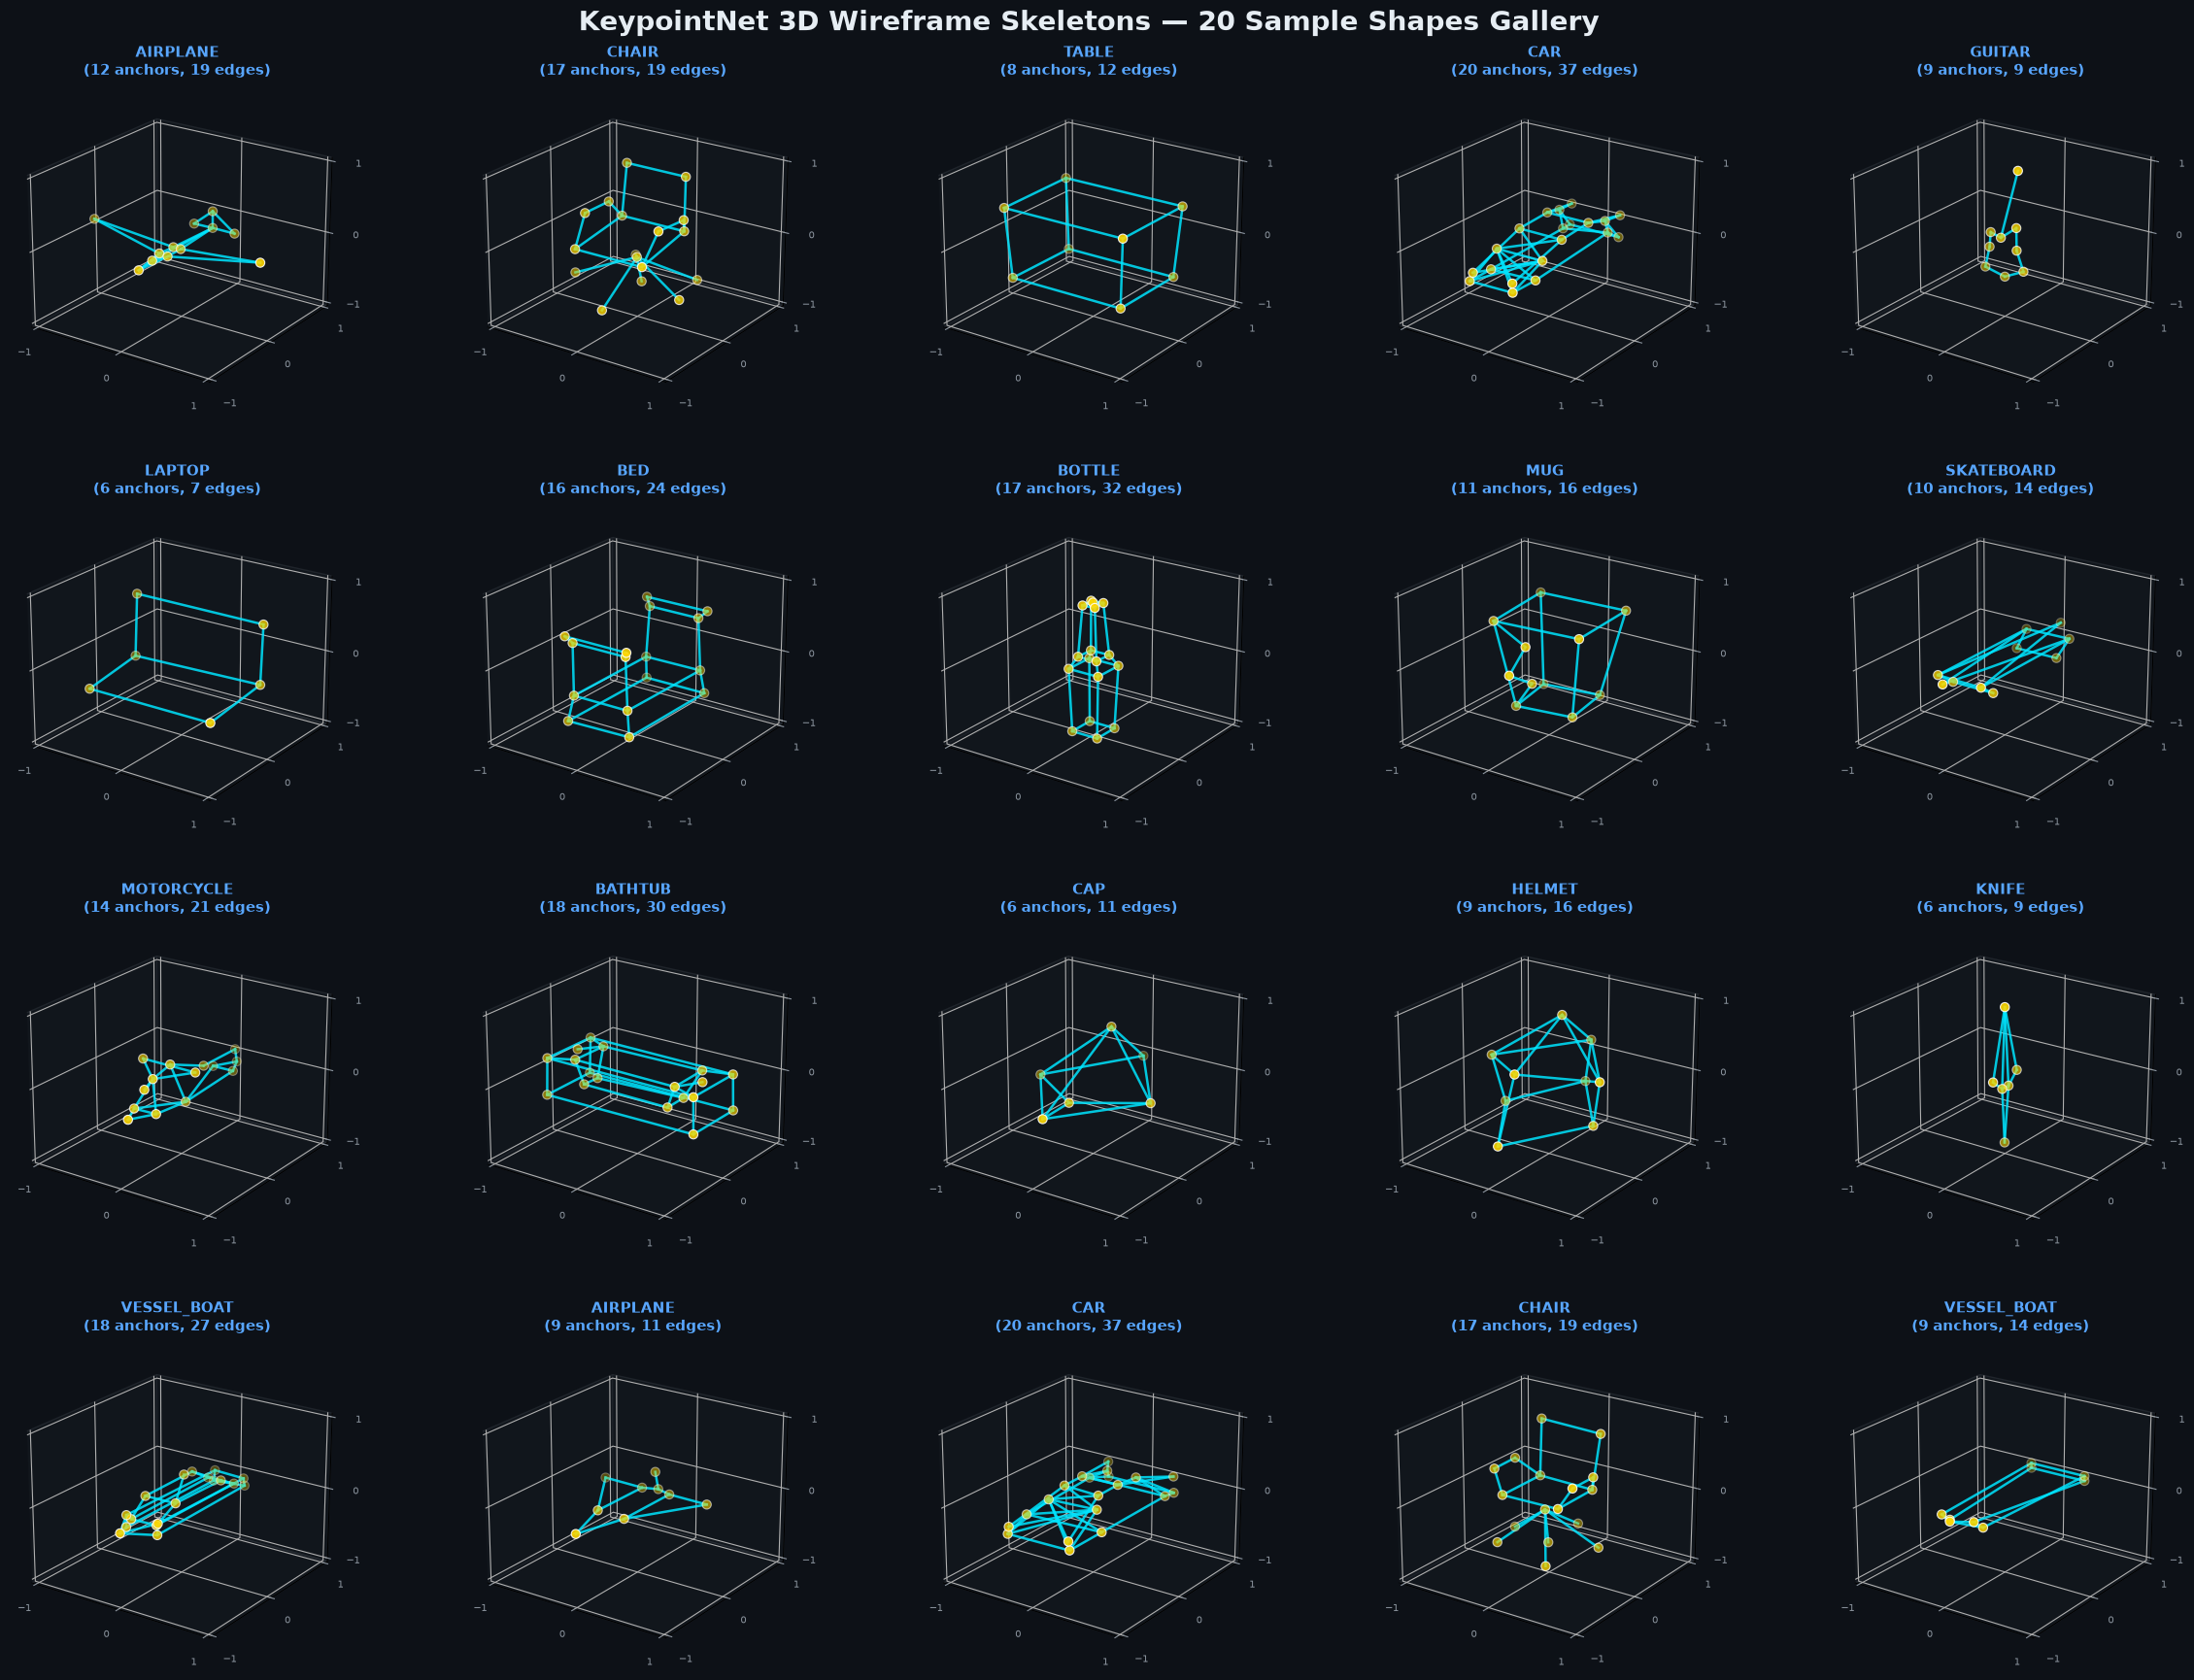

In [4]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Select 20 diverse representative samples (1 per category for all 16 categories + 4 distinct variations)
sample_keys = []
for cat in category_counts.keys():
    cat_keys = [k for k, v in dataset.items() if v.get('category') == cat]
    if cat_keys:
        sample_keys.append(cat_keys[0])

# Add 4 additional distinct variations
for extra_cat in ['airplane', 'car', 'chair', 'vessel_boat']:
    cat_keys = [k for k, v in dataset.items() if v.get('category') == extra_cat]
    if len(cat_keys) > 1:
        sample_keys.append(cat_keys[1])

sample_keys = sample_keys[:20]
print(f'Selected 20 3D wireframe samples across categories:')
for idx, key in enumerate(sample_keys, 1):
    print(f' {idx:2d}. {key:22s} ({len(dataset[key]["anchors"])} anchors, {len(dataset[key]["edges"])} edges)')

# Render high-resolution 4x5 3D Wireframe Gallery
fig = plt.figure(figsize=(24, 18), facecolor='#0D1117')
plt.subplots_adjust(wspace=0.1, hspace=0.25, top=0.94, bottom=0.03, left=0.02, right=0.98)
fig.suptitle('KeypointNet 3D Wireframe Skeletons — 20 Sample Shapes Gallery', color='#E6EDF3', fontsize=20, fontweight='bold')

for idx, key in enumerate(sample_keys):
    ax = fig.add_subplot(4, 5, idx + 1, projection='3d', facecolor='#0D1117')
    shape = dataset[key]
    anchors = np.array(shape['anchors'])
    edges = shape['edges']
    
    for i, j in edges:
        p1, p2 = anchors[i], anchors[j]
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#00E5FF', alpha=0.85, linewidth=1.8)
        
    ax.scatter(anchors[:, 0], anchors[:, 1], anchors[:, 2], color='#FFD700', s=45, edgecolors='#FFFFFF', linewidth=0.8, alpha=0.95)
    
    cat_name = shape.get('category', key.split('_')[0])
    ax.set_title(f'{cat_name.upper()}\n({len(anchors)} anchors, {len(edges)} edges)', color='#58A6FF', fontsize=11, fontweight='bold', pad=2)
    ax.set_xlim([-1.05, 1.05])
    ax.set_ylim([-1.05, 1.05])
    ax.set_zlim([-1.05, 1.05])
    ax.view_init(elev=22, azim=-55)
    
    ax.grid(True, linestyle=':', alpha=0.25, color='#30363D')
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([-1, 0, 1])
    ax.set_zticks([-1, 0, 1])
    ax.tick_params(colors='#8B949E', labelsize=7)
    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
        pane.set_facecolor('#161B22')
        pane.set_edgecolor('#30363D')

plt.savefig('assets/samples_20_wireframes_gallery.png', dpi=150, facecolor='#0D1117')
plt.show()


## Perceptual Minimum Drone Calculation ($N_{\min}$)

For human vision to perceive a 3D drone shape correctly in the night sky:
1. **Corner Anchors ($K$):** Essential for spatial extremities.
2. **Continuous Stroke Spacing ($d_{\text{gap}} \le 0.25$):** Prevents the 'constellation effect' by placing intermediate drones along edges so the human visual cortex connects adjacent points along edges rather than jumping across unrelated parts.

$$N_{\min} = K + \sum_{e=(i, j) \in \mathcal{E}} \max\left(0, \left\lceil \frac{\|P_j - P_i\|_2}{d_{\text{gap}}} \right\rceil - 1\right)$$

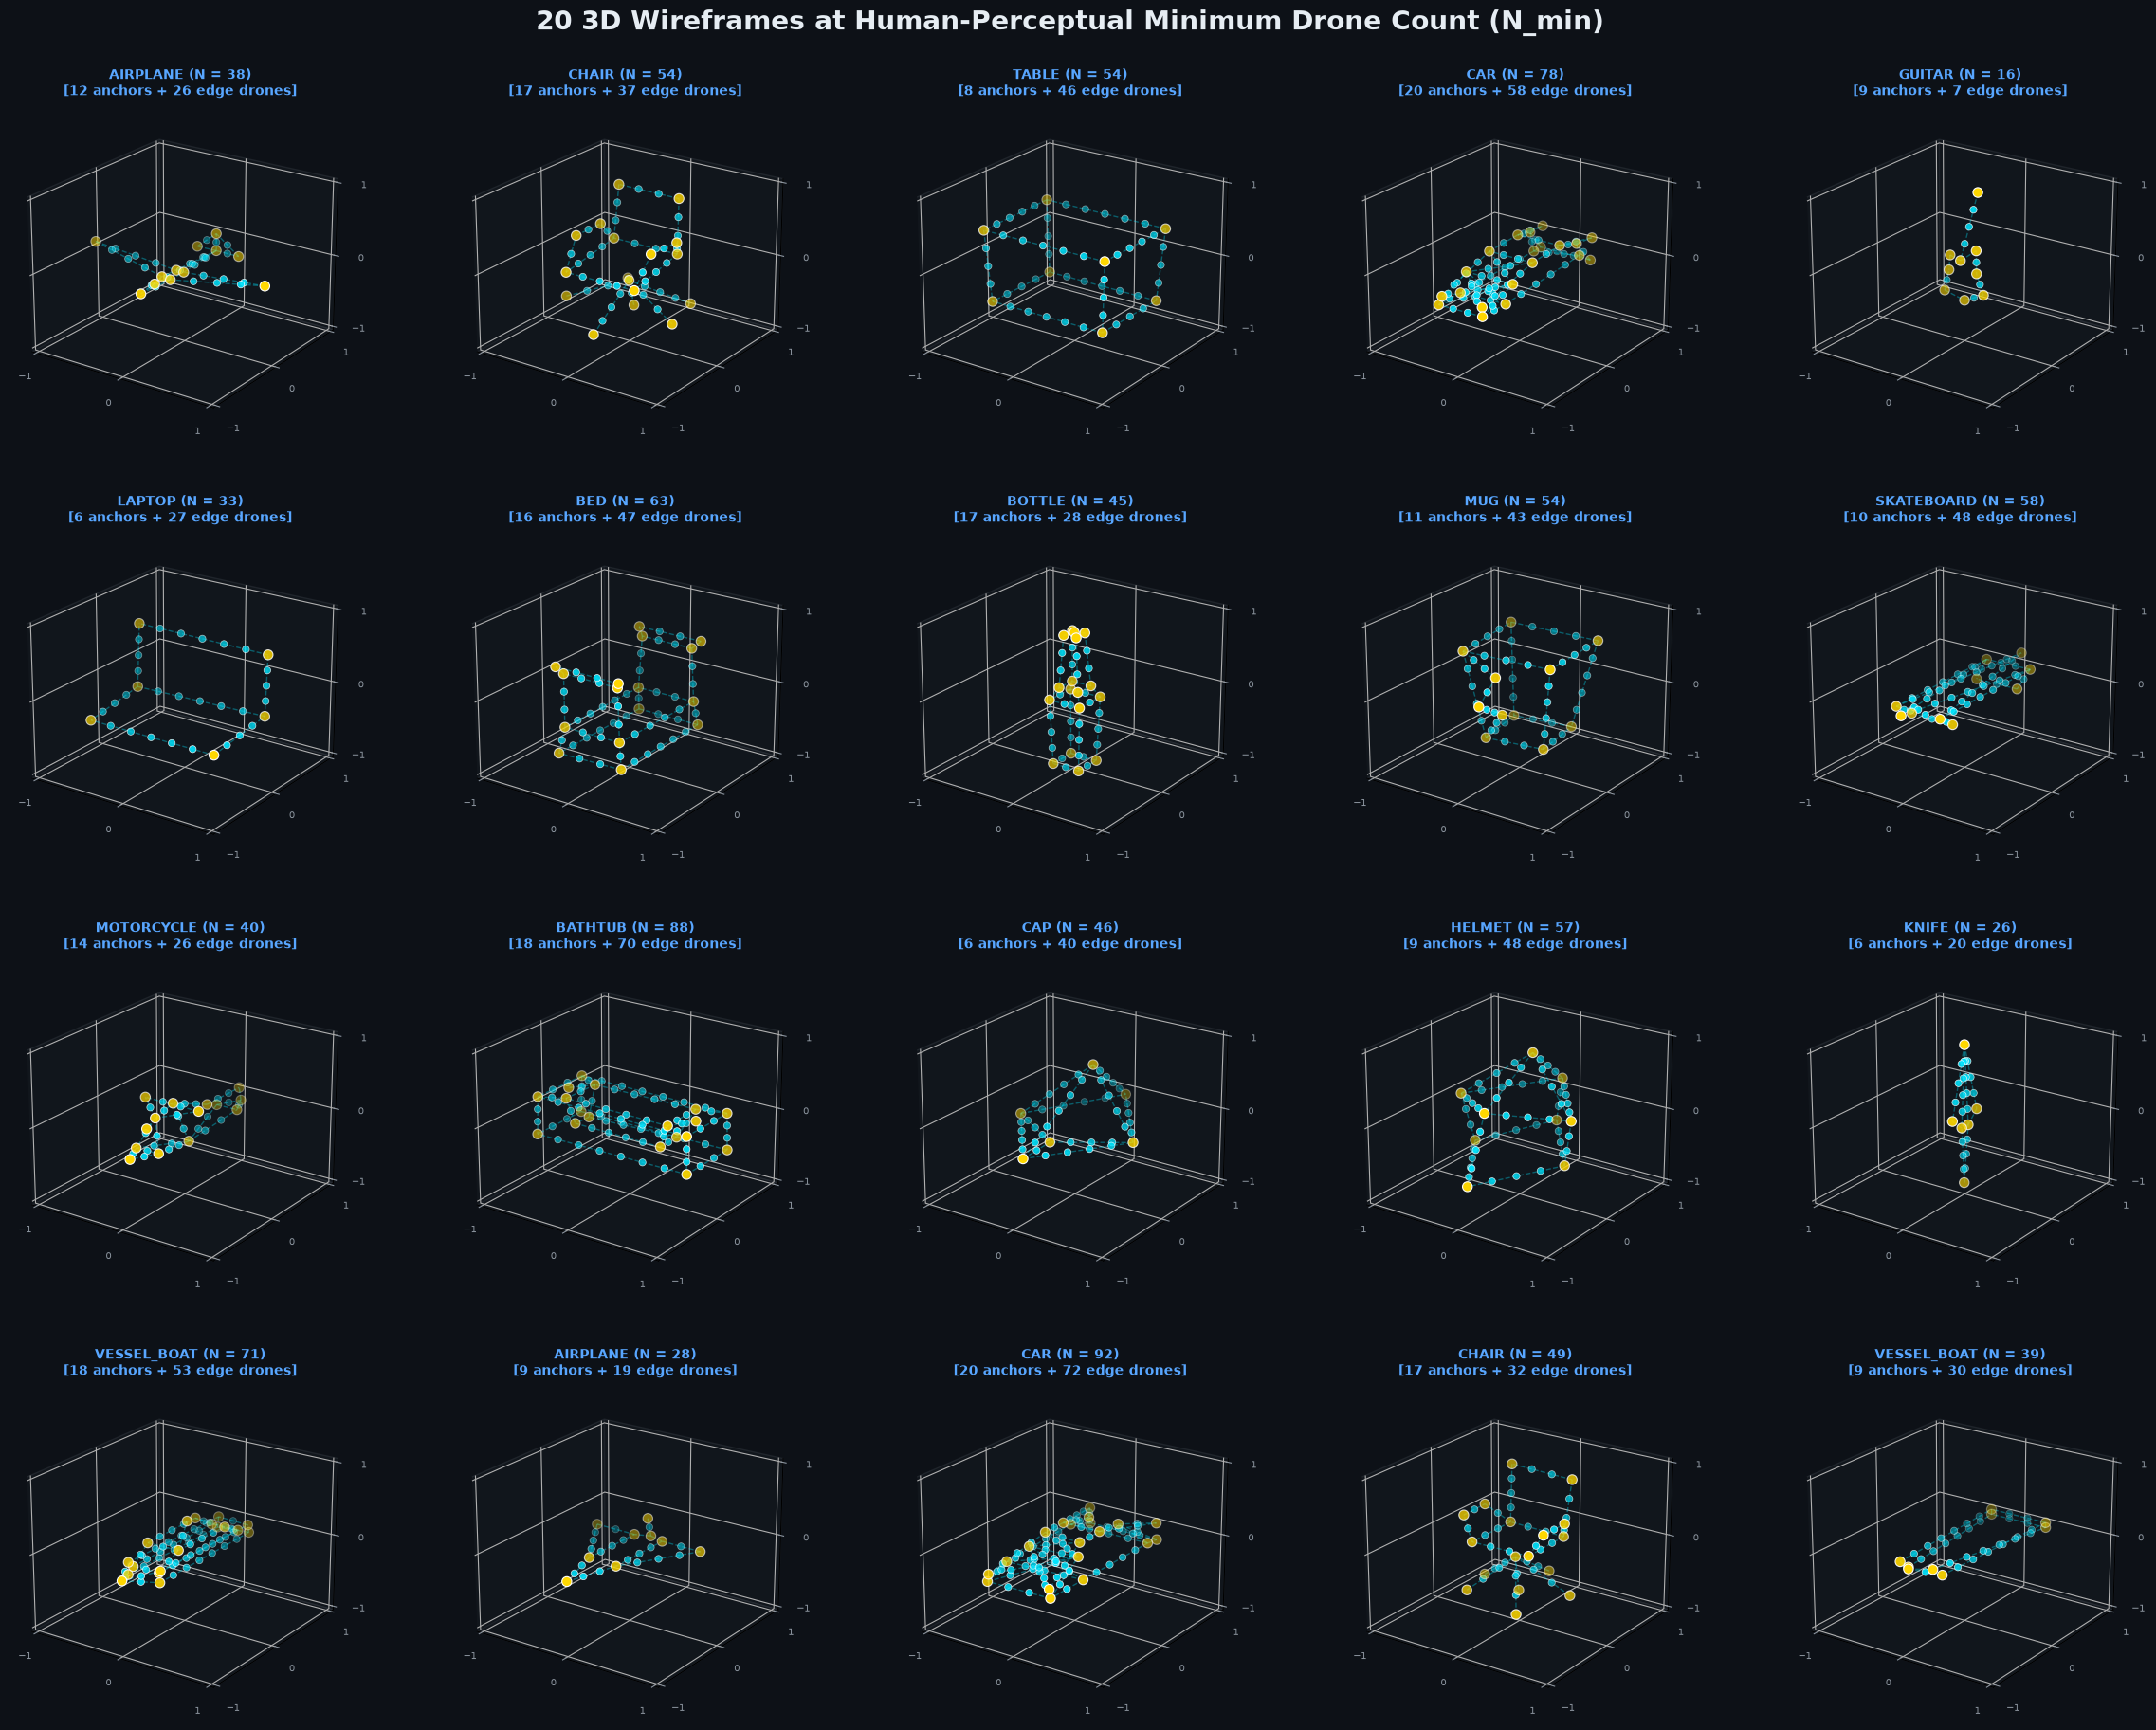

In [5]:
def build_min_drone_swarm(shape, d_gap=0.25):
    anchors = np.array(shape['anchors'], dtype=float)
    edges = shape['edges']
    K = len(anchors)
    
    # 1. Corner anchors are mandatory
    points = list(anchors)
    point_types = ['anchor'] * K
    
    # 2. Place interior edge drones so gap <= d_gap
    for i, j in edges:
        p1, p2 = anchors[i], anchors[j]
        edge_len = np.linalg.norm(p2 - p1)
        m = max(0, int(np.ceil(edge_len / d_gap)) - 1)
        for s in range(1, m + 1):
            t = s / (m + 1)
            pt = (1.0 - t) * p1 + t * p2
            points.append(pt)
            point_types.append('edge')
            
    return np.array(points), point_types

# Render the 20 samples with their exact minimum drone swarms
fig = plt.figure(figsize=(24, 19), facecolor='#0D1117')
plt.subplots_adjust(wspace=0.1, hspace=0.25, top=0.93, bottom=0.03, left=0.02, right=0.98)
fig.suptitle('20 3D Wireframes at Human-Perceptual Minimum Drone Count (N_min)', color='#E6EDF3', fontsize=20, fontweight='bold')

for idx, key in enumerate(sample_keys):
    ax = fig.add_subplot(4, 5, idx + 1, projection='3d', facecolor='#0D1117')
    shape = dataset[key]
    anchors = np.array(shape['anchors'])
    edges = shape['edges']
    
    points, types = build_min_drone_swarm(shape, d_gap=0.25)
    anchor_mask = np.array(types) == 'anchor'
    edge_mask = np.array(types) == 'edge'
    
    anchor_pts = points[anchor_mask]
    edge_pts = points[edge_mask] if np.sum(edge_mask) > 0 else np.empty((0, 3))
    
    # Draw faint wireframe guide lines (dashed)
    for i, j in edges:
        p1, p2 = anchors[i], anchors[j]
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#00E5FF', alpha=0.35, linewidth=1.0, linestyle='--')
        
    # Draw edge-interpolated drones (cyan markers)
    if len(edge_pts) > 0:
        ax.scatter(edge_pts[:, 0], edge_pts[:, 1], edge_pts[:, 2], color='#00E5FF', s=28, edgecolors='#FFFFFF', linewidth=0.5, alpha=0.95)
        
    # Draw corner anchor drones (gold markers)
    ax.scatter(anchor_pts[:, 0], anchor_pts[:, 1], anchor_pts[:, 2], color='#FFD700', s=55, edgecolors='#FFFFFF', linewidth=0.8, alpha=1.0)
    
    cat_name = shape.get('category', key.split('_')[0])
    N_total = len(points)
    K_anchors = len(anchor_pts)
    E_drones = len(edge_pts)
    
    ax.set_title(f'{cat_name.upper()} (N = {N_total})\n[{K_anchors} anchors + {E_drones} edge drones]', color='#58A6FF', fontsize=10, fontweight='bold', pad=2)
    ax.set_xlim([-1.05, 1.05])
    ax.set_ylim([-1.05, 1.05])
    ax.set_zlim([-1.05, 1.05])
    ax.view_init(elev=22, azim=-55)
    
    ax.grid(True, linestyle=':', alpha=0.25, color='#30363D')
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([-1, 0, 1])
    ax.set_zticks([-1, 0, 1])
    ax.tick_params(colors='#8B949E', labelsize=7)
    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
        pane.set_facecolor('#161B22')
        pane.set_edgecolor('#30363D')

plt.savefig('assets/samples_20_min_drones_gallery.png', dpi=150, facecolor='#0D1117')
plt.show()


In [6]:
import plotly.graph_objects as go

def plot_interactive_3d_swarm(shape_key, d_gap=0.25):
    shape = dataset[shape_key]
    points, types = build_min_drone_swarm(shape, d_gap=d_gap)
    anchors = np.array(shape['anchors'])
    edges = shape['edges']
    
    # Build line coordinates with None separators
    edge_x, edge_y, edge_z = [], [], []
    for i, j in edges:
        edge_x.extend([anchors[i, 0], anchors[j, 0], None])
        edge_y.extend([anchors[i, 1], anchors[j, 1], None])
        edge_z.extend([anchors[i, 2], anchors[j, 2], None])
        
    lines_trace = go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='rgba(0, 229, 255, 0.4)', width=3, dash='dash'),
        name='Wireframe Edge Guides',
        hoverinfo='none'
    )
    
    anchor_mask = np.array(types) == 'anchor'
    edge_mask = np.array(types) == 'edge'
    
    anchor_trace = go.Scatter3d(
        x=points[anchor_mask, 0], y=points[anchor_mask, 1], z=points[anchor_mask, 2],
        mode='markers',
        marker=dict(size=7, color='#FFD700', symbol='circle', line=dict(color='#FFFFFF', width=1)),
        name='Corner Anchor Drones',
        hoverinfo='text',
        text=[f'Anchor Drone {i}' for i in range(np.sum(anchor_mask))]
    )
    
    traces = [lines_trace, anchor_trace]
    if np.sum(edge_mask) > 0:
        edge_trace = go.Scatter3d(
            x=points[edge_mask, 0], y=points[edge_mask, 1], z=points[edge_mask, 2],
            mode='markers',
            marker=dict(size=5, color='#00E5FF', symbol='circle'),
            name='Edge Interpolated Drones',
            hoverinfo='text',
            text=[f'Edge Drone {i}' for i in range(np.sum(edge_mask))]
        )
        traces.append(edge_trace)
        
    fig = go.Figure(data=traces)
    fig.update_layout(
        title=f'Interactive Swarm: {shape_key} (Total Drones N = {len(points)})',
        template='plotly_dark',
        paper_bgcolor='#0D1117',
        scene=dict(
            aspectmode='cube',
            xaxis=dict(range=[-1.1, 1.1], gridcolor='#30363D', backgroundcolor='#161B22'),
            yaxis=dict(range=[-1.1, 1.1], gridcolor='#30363D', backgroundcolor='#161B22'),
            zaxis=dict(range=[-1.1, 1.1], gridcolor='#30363D', backgroundcolor='#161B22')
        ),
        margin=dict(l=0, r=0, b=0, t=40),
        height=600
    )
    return fig

# Interactive view of Airplane swarm formation
interactive_fig = plot_interactive_3d_swarm(sample_keys[0])
interactive_fig.show()
